# GenMol - Basics

## Setup
This notebook assumes that the NIM is running! Ports for the NIMs:
- AlphaFold2: 8081
- MolMIM: 8082
- **GenMOL: 8083**
- diffdock : 8084


In [1]:
#!pip install safe-mol datamol pandas numpy rdkit matplotlib 2>/dev/null | tail -n 1

In [2]:
#!pip install safe-mol datamol 2>/dev/null | tail -n 1

In [3]:
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.utils import Utils

from rdkit import Chem
from rdkit.Chem import Draw

# SAFE <> SMILES conversion
import safe as sf
import datamol as dm

import pandas as pd

GENMOL_HOST = 'http://127.0.0.1:8083'
gm = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")


## Test NIM availability

In [4]:
!curl {GENMOL_HOST}/v1/health/ready

true

## Define Seeds and used Seed for generation

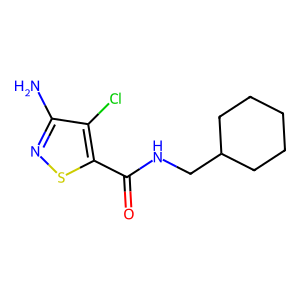

In [5]:
#Seed 1
m1 = "NC1=NSC(C(=O)NCC2CCCCC2)=C1Cl"
m1_name = "BCS-CU93684"

seed_mol_m1  = dm.to_mol(m1)
display(dm.to_image(seed_mol_m1))

In [6]:
# define the seed to be used in the notebook
m_seq = m1
seed_mol = seed_mol_m1

## check SAFE conversion & Reconstruction

In [7]:
safe_str = sf.encode(seed_mol)
print(f"SMILES: {m_seq}")
print(f"SAFE:   {safe_str}\n represented using {len(safe_str.split('.'))} fragments")

SMILES: NC1=NSC(C(=O)NCC2CCCCC2)=C1Cl
SAFE:   Nc1nsc5c1Cl.C16CCCCC1.C35=O.N34.C46
 represented using 5 fragments


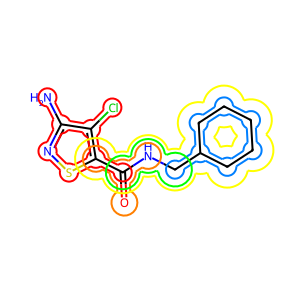

In [8]:
sf.to_image(safe_str)

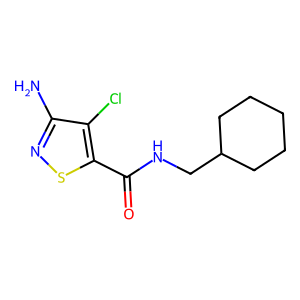

In [9]:
testreconstructed = dm.to_mol(safe_str)
display(dm.to_image(testreconstructed))

# Base Generation

Just a test generation to see if model is woring... basically the "de novo" way to generate molecules

In [10]:
result = gm.produce([m_seq], 10)

In [11]:
print(result[0])
print(m_seq)

CCCC[NH+]1CCN(C(=O)c2ncsc2C)CC1
NC1=NSC(C(=O)NCC2CCCCC2)=C1Cl


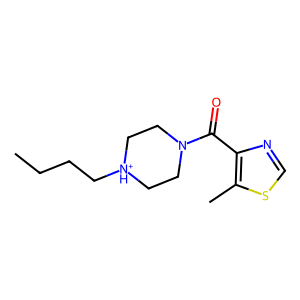

In [12]:
res_mol  = dm.to_mol(result[0])
display(dm.to_image(res_mol))

# Motif-Extension or Scaffold-Decoration

input is single fragment

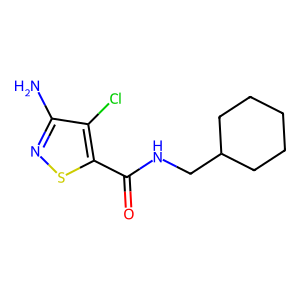

In [13]:
#draw original mol
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

### Example 1: first fragment

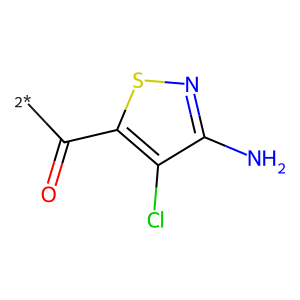

In [16]:
# add wildcard to a fragment
smiles_masked_1 = 'NC1=NSC(C([2*])=O)=C1Cl'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_1))

In [17]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_1)
safe_to_gen
molecules_e1 = gm.inference(smiles = safe_to_gen + '.[*{8-20}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e1)

41

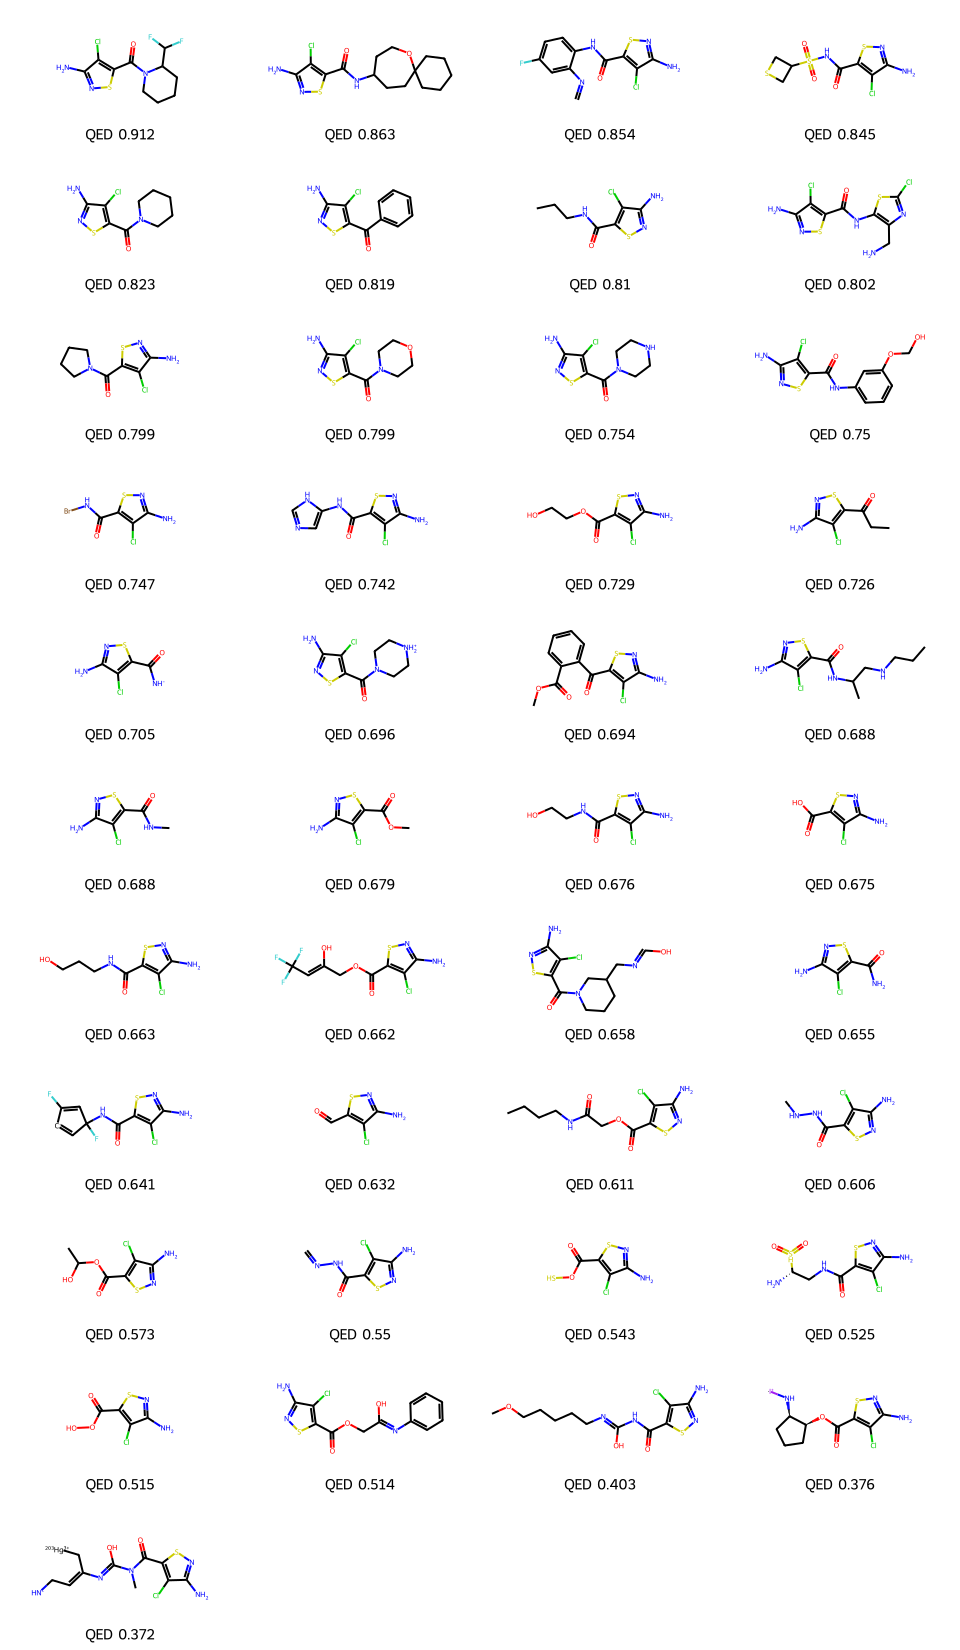

In [18]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e1]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e1])

In [19]:
# Create a DataFrame + add results
df_results = pd.DataFrame(molecules_e1)

## Example 2: second fragment

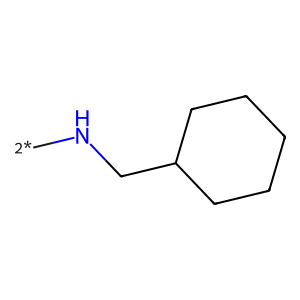

In [20]:
# add wildcard to a fragment
smiles_masked_2 = '[2*]NCC1CCCCC1'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_2))

In [21]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_2)
safe_to_gen
molecules_e2 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e2)

46

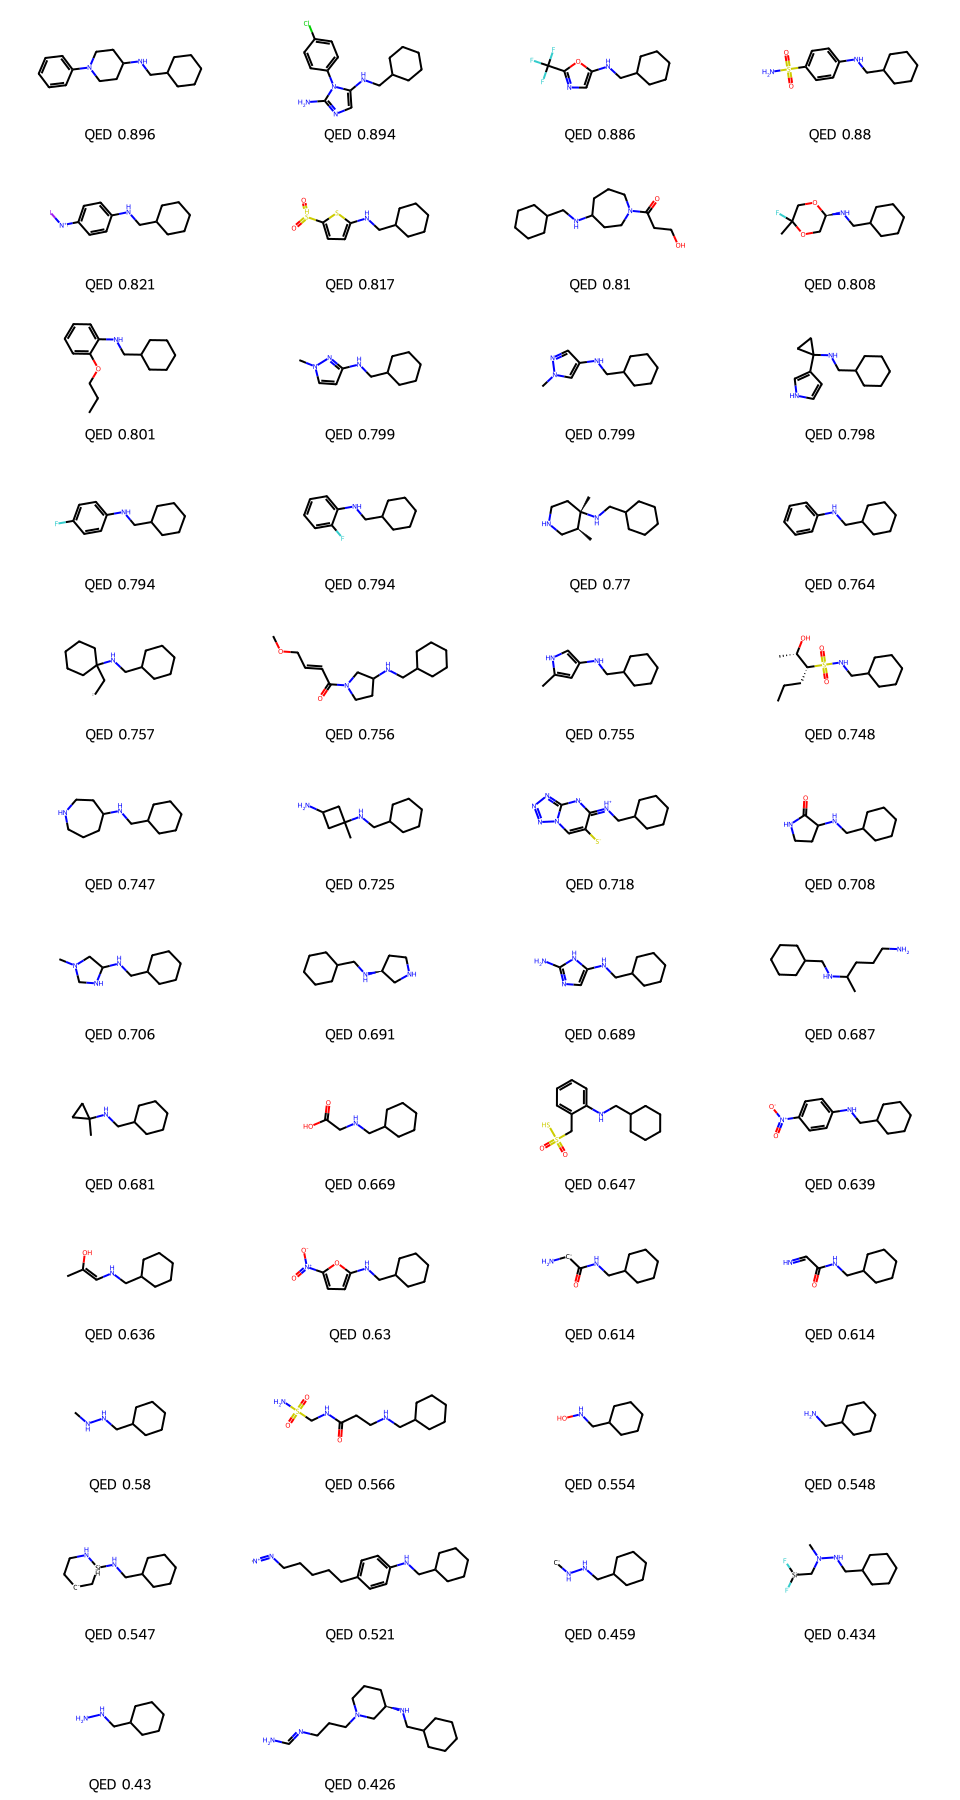

In [22]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e2]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e2])

In [23]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e2)], ignore_index=True)

In [24]:
len(df_results)

87

## Example 3: third fragment

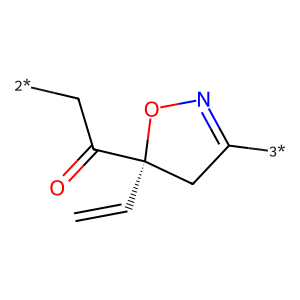

In [28]:
# add wildcard to a fragment
#smiles_masked_3 = '[2*]CC(=O)[C@@]1(CC([3*])=NO1)C=C'
Draw.MolToImage(Chem.MolFromSmiles(smiles_masked_3))

In [31]:
# generate with the masked smiels adding the wilcard to the ends
safe_to_gen = Utils.smiles2safe(smiles_masked_3)
safe_to_gen
molecules_e3 = gm.inference(smiles = safe_to_gen + '.[*{10-25}]', num_molecules = 100, temperature = 2.0, noise = 1.0)
len(molecules_e3)

58

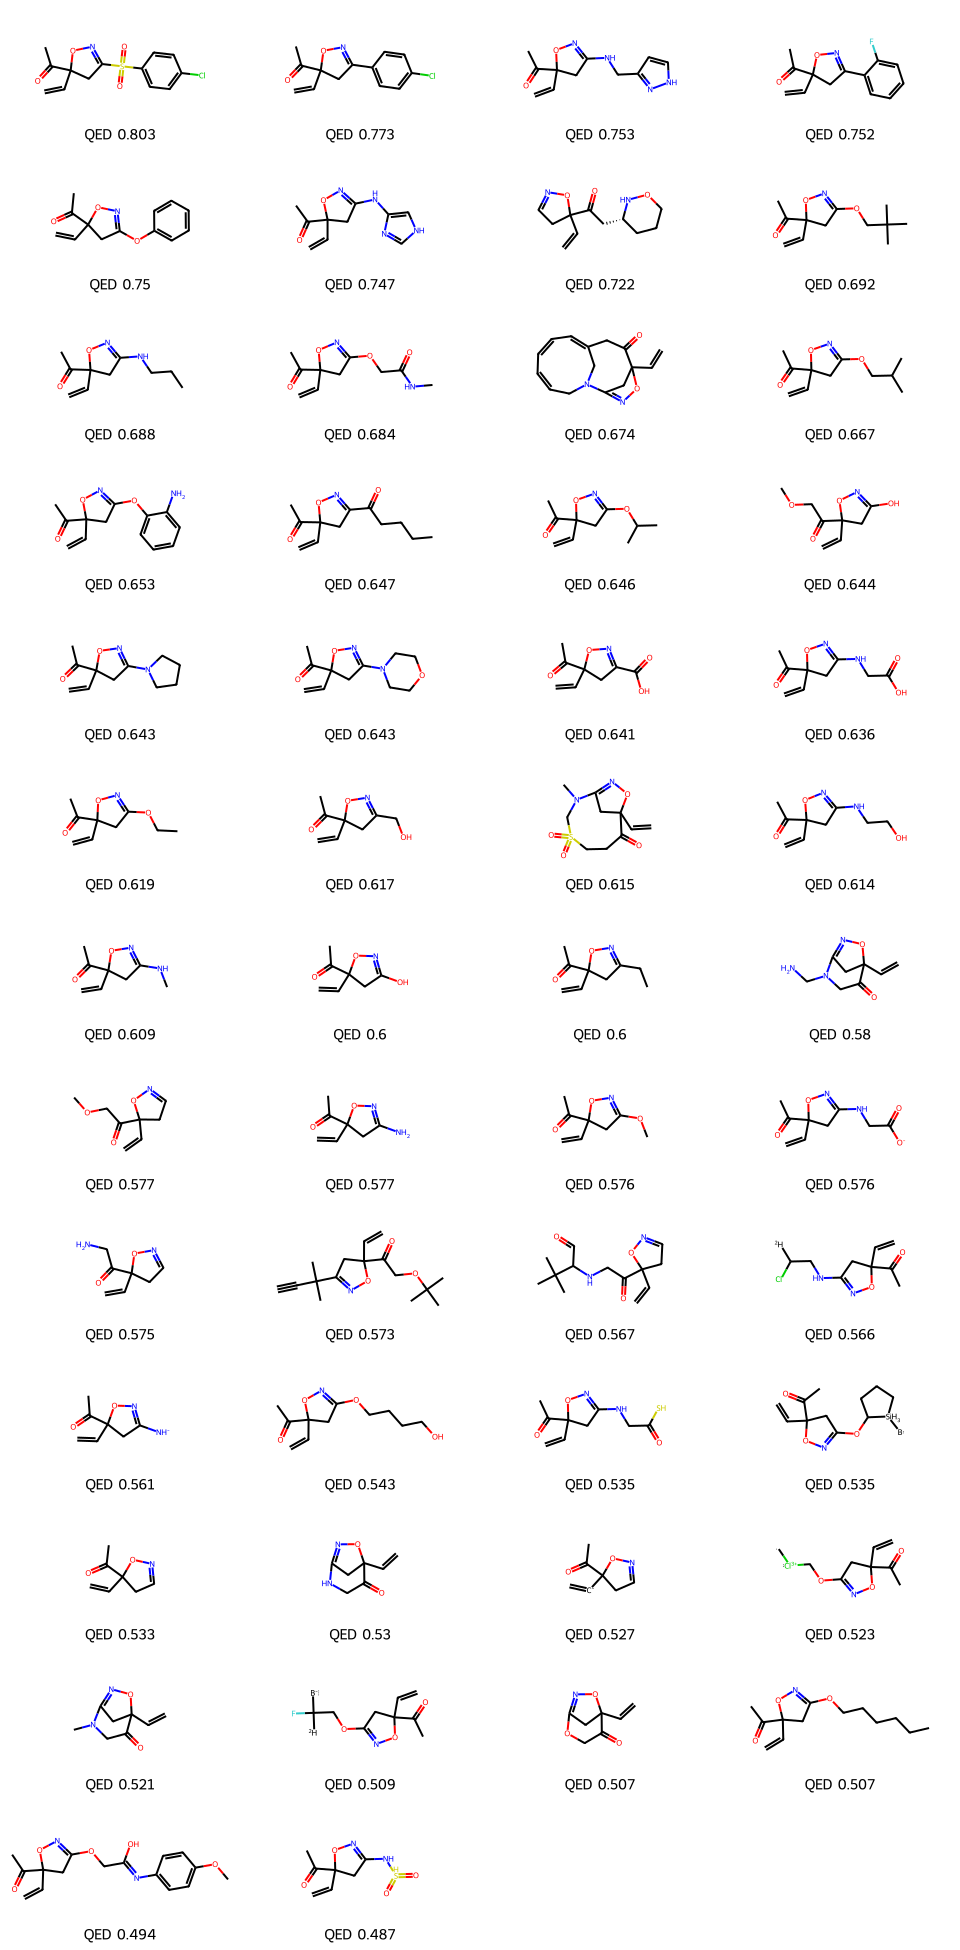

In [36]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e3]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e3])

In [38]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e3)], ignore_index=True)

In [39]:
len(df_results)

98

# Fragment based generation 
(Linker generation / Scaffold morphing)

## Mask at the end

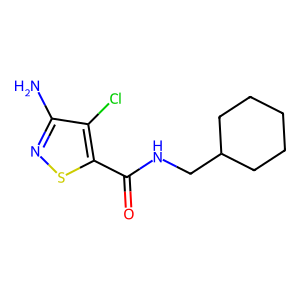

In [25]:
smiles_full = m_seq
Draw.MolToImage(Chem.MolFromSmiles(smiles_full))

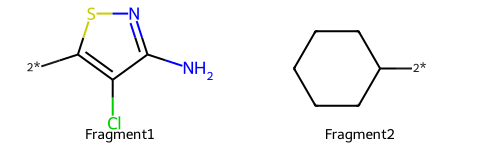

In [31]:
frag1, frag2 = 'NC1=NSC([2*])=C1Cl', '[2*]C1CCCCC1' 

Draw.MolsToGridImage([Chem.MolFromSmiles(frag1), Chem.MolFromSmiles(frag2)], 
                      molsPerRow=2, subImgSize=(240, 150), legends=['Fragment1', 'Fragment2'])

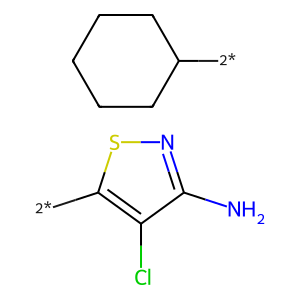

In [32]:
smiles_joint = '.'.join([frag1, frag2])
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [33]:
# mask at the end
input_text = Utils.smiles2safe(smiles_joint) + '.[*{5-18}]'
input_text

'Nc1nsc2c1Cl.C13CCCCC1.[*{5-18}]'

In [34]:
molecules_e4 = gm.inference(smiles=input_text, temperature =2.0, noise =1.0, num_molecules=1000, step_size=1)
len(molecules_e4)

53

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/rdkit/Chem/Draw/IPythonConsole.py:261: UserWarning: Truncating the list of molecules to be displayed to 50. Change the maxMols value to display more.
  warnings.warn(


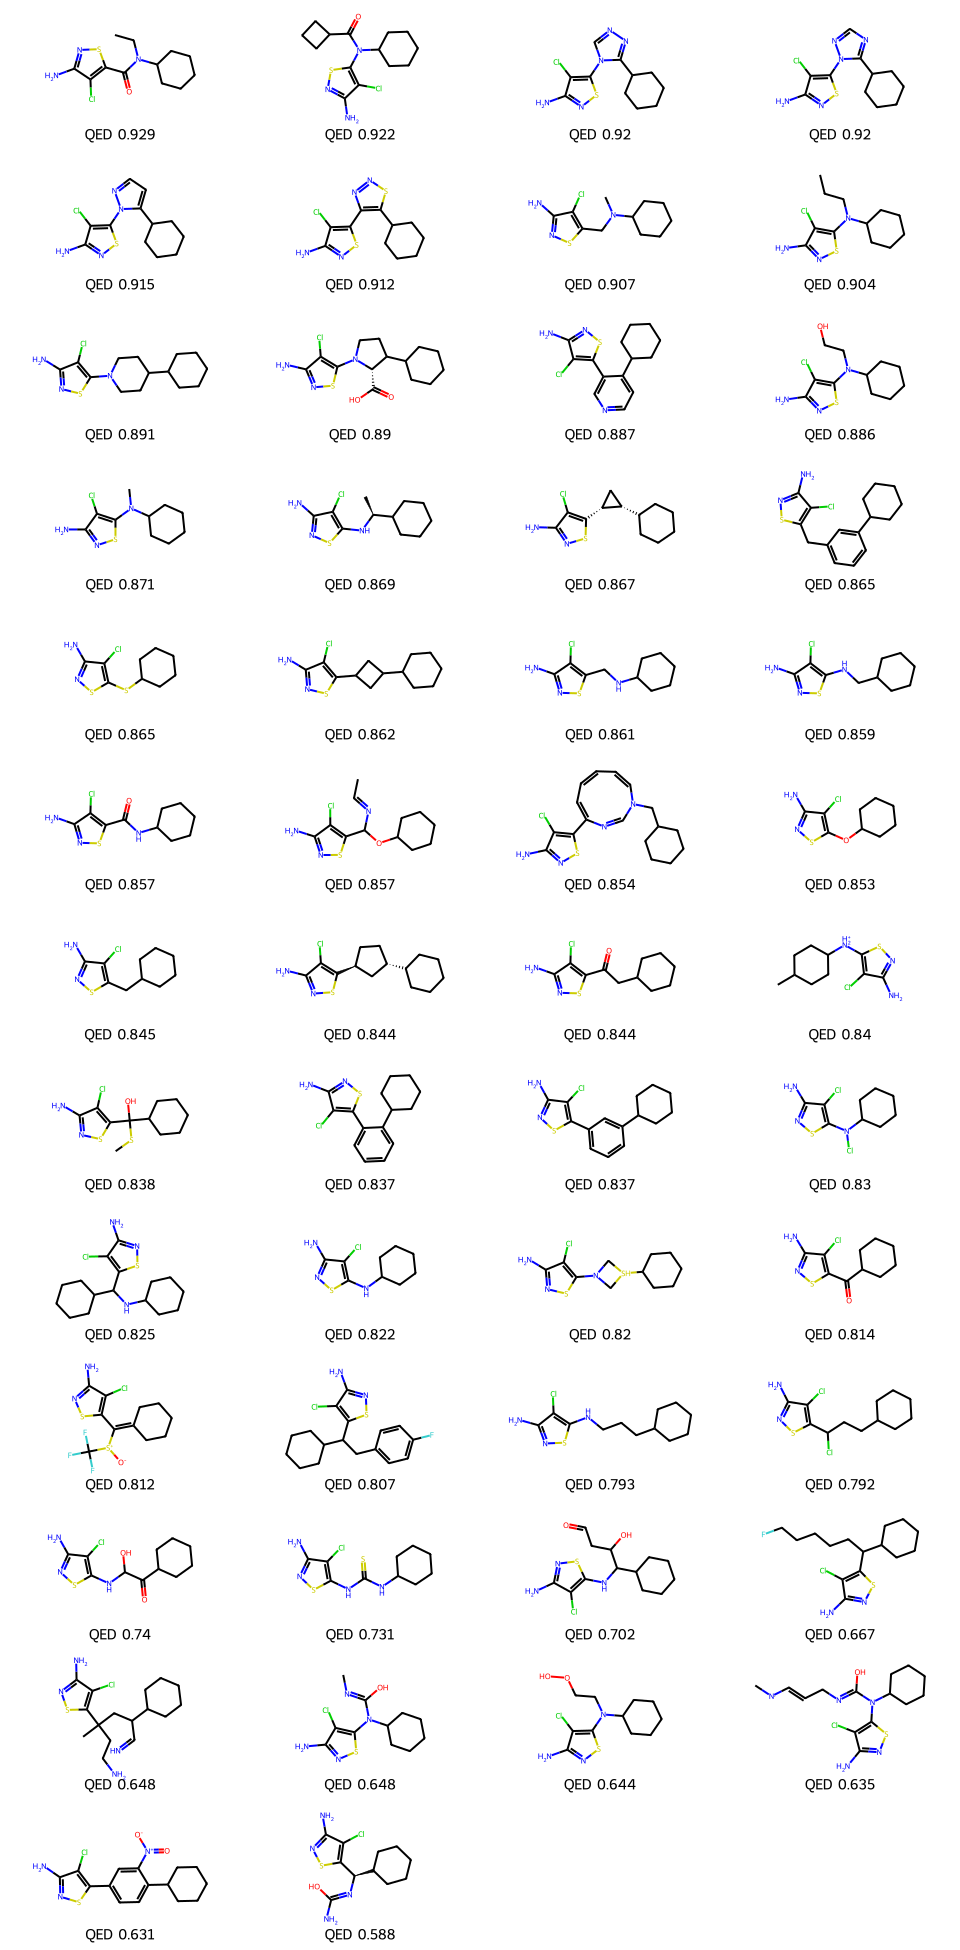

In [35]:
# Visualize the  molecules generated
ms = [Chem.MolFromSmiles(_['smiles']) for _ in molecules_e4]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(240, 150), legends=['QED ' + str(_['score']) for _ in molecules_e4])

In [36]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e4)], ignore_index=True)
print(len(df_results))
df_results.head()

140


,smiles,score
0,Nc1nsc(C(=O)N2CCCCC2C(F)F)c1Cl,0.912
1,Nc1nsc(C(=O)NC2CCOC3(CCCCC3)CC2)c1Cl,0.863
2,C=Nc1cc(F)ccc1NC(=O)c1snc(N)c1Cl,0.854
3,Nc1nsc(C(=O)NS(=O)(=O)C2CSC2)c1Cl,0.845
4,Nc1nsc(C(=O)N2CCCCC2)c1Cl,0.823


## Mask in the center

NC1=NSC([2*])=C1Cl.[2*]C1CCCCC1


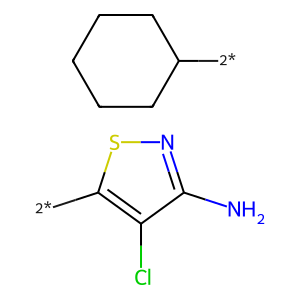

In [37]:
smiles_joint = '.'.join([frag1, frag2])
print(smiles_joint)
Draw.MolToImage(Chem.MolFromSmiles(smiles_joint))

In [38]:
#what sub-fragments are in frag1 
text_frag1 = Utils.smiles2safe(frag1).split('.')
text_frag1

['Nc1nsc2c1Cl']

In [39]:
#what sub-fragments are in frag2
text_frag2 = Utils.smiles2safe(frag2).split('.')
text_frag2

['C12CCCCC1']

In [40]:
#what sub-fragments are in the full mol?
input_text = Utils.smiles2safe(smiles_joint).split('.')
input_text

['Nc1nsc2c1Cl', 'C13CCCCC1']

In [41]:
input_text[:1]

['Nc1nsc2c1Cl']

In [42]:
# select where to set mask
input_w_mask = '.'.join(input_text[:1]) + '.[*{5-20}].' + '.'.join(input_text[1:])
input_w_mask

'Nc1nsc2c1Cl.[*{5-20}].C13CCCCC1'

In [43]:
molecules_e5 = gm.inference(smiles = input_w_mask, temperature = 2.0, noise = 1.0, num_molecules=1000)
len(molecules_e5)

497

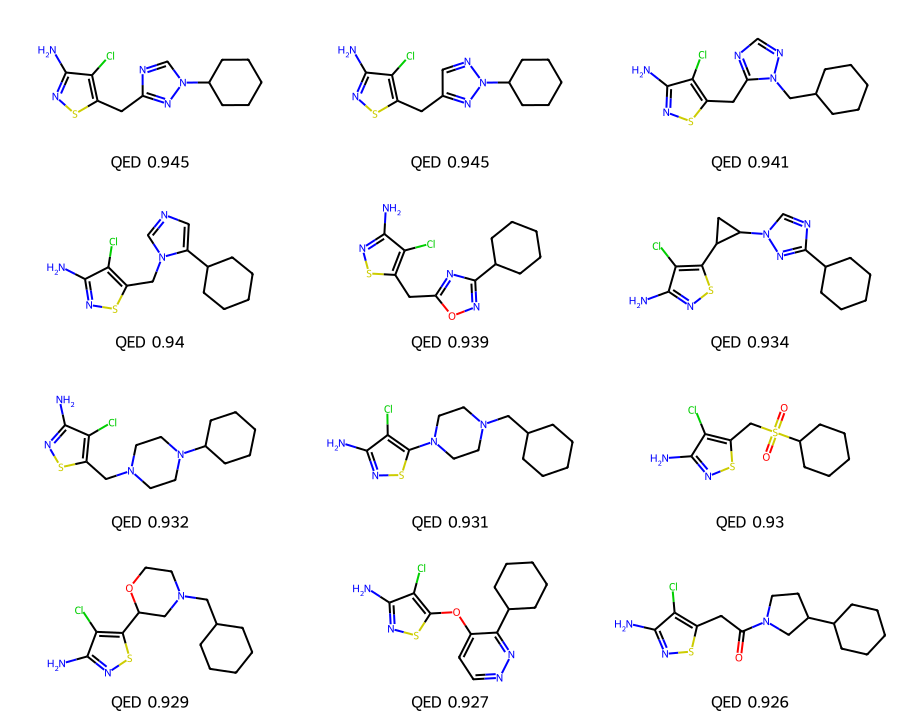

In [44]:
Draw.MolsToGridImage([Chem.MolFromSmiles(_['smiles']) for _ in molecules_e5[:12]], 
                      molsPerRow=3, subImgSize=(300, 180), legends=['QED ' + str(_['score']) for _ in molecules_e5[:12]])

In [45]:
df_results = pd.concat([df_results, pd.DataFrame(molecules_e5)], ignore_index=True)
print(len(df_results))
df_results.head()

637


,smiles,score
0,Nc1nsc(C(=O)N2CCCCC2C(F)F)c1Cl,0.912
1,Nc1nsc(C(=O)NC2CCOC3(CCCCC3)CC2)c1Cl,0.863
2,C=Nc1cc(F)ccc1NC(=O)c1snc(N)c1Cl,0.854
3,Nc1nsc(C(=O)NS(=O)(=O)C2CSC2)c1Cl,0.845
4,Nc1nsc(C(=O)N2CCCCC2)c1Cl,0.823


In [46]:
m1_name

'BCS-CU93684'

In [47]:
#df_results.to_csv(f"../../data/interim/genmol/{m1_name}_R1_testmulti.csv", index=False)